# Retail Banking — EDA and Data Cleaning
**Module:** Build an AI Model to Forecast Trends and Detect Opportunities in Retail Banking

This notebook loads the supplied customer and monthly transaction CSV files, profiles them, checks data quality, converts dates, merges datasets, performs exploratory analysis, and exports cleaned outputs.

**Before running:** keep `retail_banking_customers.csv` and `retail_banking_transactions.csv` in the same folder as this notebook. Cleaning decisions are conservative: do not delete valid records or treat unusual values as errors without business justification.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme()

CUSTOMER_FILE = Path("retail_banking_customers.csv")
TRANSACTION_FILE = Path("retail_banking_transactions.csv")

customers_raw = pd.read_csv(CUSTOMER_FILE)
transactions_raw = pd.read_csv(TRANSACTION_FILE)

print("Customers shape:", customers_raw.shape)
print("Transactions shape:", transactions_raw.shape)
display(customers_raw.head())
display(transactions_raw.head())


Customers shape: (5000, 10)
Transactions shape: (24000, 3)


,customer_id,age,region,preferred_channel,monthly_transactions_avg,avg_monthly_balance,num_products_held,digital_adoption_score,credit_card_issued,loan_taken
0,CUST100000,56,North,ATM,29,36460,1,0.56,0,0
1,CUST100001,69,South,Branch,15,54595,3,0.74,1,0
2,CUST100002,46,West,Online Banking,12,55180,3,0.08,0,0
3,CUST100003,32,North,Branch,23,50150,2,0.52,0,0
4,CUST100004,60,Central,Online Banking,18,61720,2,0.62,1,0


,customer_id,month,monthly_transactions
0,CUST102702,2022-01,11
1,CUST102702,2022-02,11
2,CUST102702,2022-03,17
3,CUST102702,2022-04,15
4,CUST102702,2022-05,16


In [2]:

print("===== CUSTOMER DATASET INFO =====")
customers_raw.info()

print("\n===== TRANSACTION DATASET INFO =====")
transactions_raw.info()


===== CUSTOMER DATASET INFO =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               5000 non-null   object 
 1   age                       5000 non-null   int64  
 2   region                    5000 non-null   object 
 3   preferred_channel         5000 non-null   object 
 4   monthly_transactions_avg  5000 non-null   int64  
 5   avg_monthly_balance       5000 non-null   int64  
 6   num_products_held         5000 non-null   int64  
 7   digital_adoption_score    5000 non-null   float64
 8   credit_card_issued        5000 non-null   int64  
 9   loan_taken                5000 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 390.8+ KB

===== TRANSACTION DATASET INFO =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24000 entries, 0 to 23999
Data columns (total 3

In [3]:

print("Missing values in customer dataset:")
display(customers_raw.isnull().sum())

print("Missing values in transaction dataset:")
display(transactions_raw.isnull().sum())


Missing values in customer dataset:


customer_id                 0
age                         0
region                      0
preferred_channel           0
monthly_transactions_avg    0
avg_monthly_balance         0
num_products_held           0
digital_adoption_score      0
credit_card_issued          0
loan_taken                  0
dtype: int64

Missing values in transaction dataset:


customer_id             0
month                   0
monthly_transactions    0
dtype: int64

In [4]:

print("Duplicate customer rows:", customers_raw.duplicated().sum())
print("Duplicate transaction rows:", transactions_raw.duplicated().sum())


Duplicate customer rows: 0
Duplicate transaction rows: 0


In [5]:

print("===== CUSTOMER NUMERICAL SUMMARY =====")
display(customers_raw.describe())

print("===== TRANSACTION NUMERICAL SUMMARY =====")
display(transactions_raw.describe())


===== CUSTOMER NUMERICAL SUMMARY =====


,age,monthly_transactions_avg,avg_monthly_balance,num_products_held,digital_adoption_score,credit_card_issued,loan_taken
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.584600,20.018600,50151.194000,1.990600,0.496934,0.300400,0.199400
std,14.919094,4.451676,15005.133443,1.000756,0.288547,0.458478,0.399589
min,18.000000,6.000000,1000.000000,1.000000,0.000000,0.000000,0.000000
25%,31.000000,17.000000,39997.000000,1.000000,0.250000,0.000000,0.000000
50%,43.000000,20.000000,49902.000000,2.000000,0.500000,0.000000,0.000000
75%,56.000000,23.000000,60218.500000,3.000000,0.750000,1.000000,0.000000
max,69.000000,36.000000,107100.000000,4.000000,1.000000,1.000000,1.000000


===== TRANSACTION NUMERICAL SUMMARY =====


,monthly_transactions
count,24000.000000
mean,20.099458
std,6.899025
min,0.000000
25%,15.000000
50%,20.000000
75%,25.000000
max,39.000000


In [6]:

print("===== CUSTOMER REGIONS =====")
display(customers_raw["region"].value_counts())

print("\n===== PREFERRED CHANNELS =====")
display(customers_raw["preferred_channel"].value_counts())

print("\n===== TRANSACTION MONTHS =====")
print(sorted(transactions_raw["month"].unique()))


===== CUSTOMER REGIONS =====


region
South      1067
Central     999
North       989
West        979
East        966
Name: count, dtype: int64


===== PREFERRED CHANNELS =====


preferred_channel
Branch            1303
Online Banking    1263
ATM               1234
Mobile App        1200
Name: count, dtype: int64


===== TRANSACTION MONTHS =====
['2022-01', '2022-02', '2022-03', '2022-04', '2022-05', '2022-06', '2022-07', '2022-08', '2022-09', '2022-10', '2022-11', '2022-12', '2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07', '2023-08', '2023-09', '2023-10', '2023-11', '2023-12']


In [7]:

print("===== CUSTOMER VALUE CHECKS =====")

print("Age outside 18–100:",
      (~customers_raw["age"].between(18, 100)).sum())

print("Negative balances:",
      (customers_raw["avg_monthly_balance"] < 0).sum())

print("Invalid digital adoption scores:",
      (~customers_raw["digital_adoption_score"].between(0, 1)).sum())

print("Invalid credit card values:",
      (~customers_raw["credit_card_issued"].isin([0, 1])).sum())

print("Invalid loan values:",
      (~customers_raw["loan_taken"].isin([0, 1])).sum())

print("\n===== TRANSACTION VALUE CHECKS =====")
print("Negative monthly transactions:",
      (transactions_raw["monthly_transactions"] < 0).sum())


===== CUSTOMER VALUE CHECKS =====
Age outside 18–100: 0
Negative balances: 0
Invalid digital adoption scores: 0
Invalid credit card values: 0
Invalid loan values: 0

===== TRANSACTION VALUE CHECKS =====
Negative monthly transactions: 0


In [8]:

print("Total transaction rows:", len(transactions_raw))

print("Unique customers in transactions:",
      transactions_raw["customer_id"].nunique())

print("Unique months:",
      transactions_raw["month"].nunique())

print("Duplicate customer-month pairs:",
      transactions_raw.duplicated(
          subset=["customer_id", "month"]
      ).sum())

print("Customers in customer dataset:",
      customers_raw["customer_id"].nunique())

print("Transaction customer IDs missing from customer dataset:",
      (~transactions_raw["customer_id"].isin(
          customers_raw["customer_id"]
      )).sum())


Total transaction rows: 24000
Unique customers in transactions: 1000
Unique months: 24
Duplicate customer-month pairs: 0
Customers in customer dataset: 5000
Transaction customer IDs missing from customer dataset: 0


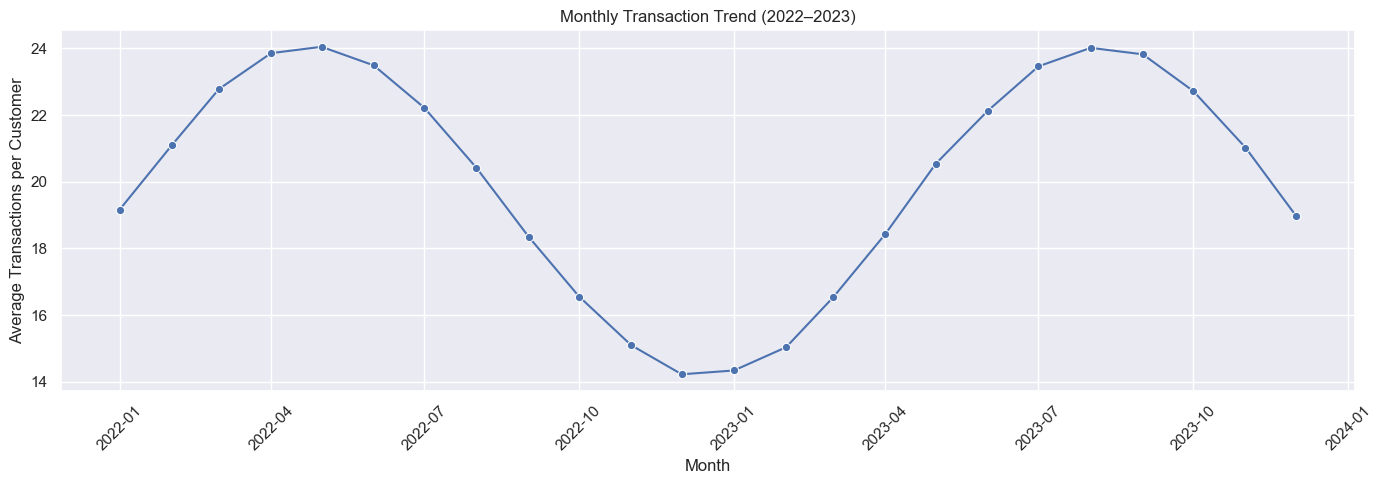

In [9]:

# Calculate average monthly transactions for each month
monthly_trend = (
    transactions_raw
    .groupby("month")["monthly_transactions"]
    .mean()
    .reset_index()
)

# Sort months chronologically
monthly_trend["month"] = pd.to_datetime(
    monthly_trend["month"], format="%Y-%m"
)
monthly_trend = monthly_trend.sort_values("month")

# Plot the trend
plt.figure(figsize=(14, 5))
sns.lineplot(
    data=monthly_trend,
    x="month",
    y="monthly_transactions",
    marker="o"
)

plt.title("Monthly Transaction Trend (2022–2023)")
plt.xlabel("Month")
plt.ylabel("Average Transactions per Customer")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [10]:

# Display average monthly transactions
print("Monthly average transaction counts:")

display(
    monthly_trend.assign(
        month=monthly_trend["month"].dt.strftime("%Y-%m")
    ).round(2)
)

# Find the highest and lowest months
highest_month = monthly_trend.loc[
    monthly_trend["monthly_transactions"].idxmax()
]

lowest_month = monthly_trend.loc[
    monthly_trend["monthly_transactions"].idxmin()
]

print("\nHighest average transaction month:")
print(
    highest_month["month"].strftime("%Y-%m"),
    round(highest_month["monthly_transactions"], 2)
)

print("\nLowest average transaction month:")
print(
    lowest_month["month"].strftime("%Y-%m"),
    round(lowest_month["monthly_transactions"], 2)
)


Monthly average transaction counts:


,month,monthly_transactions
0,2022-01,19.16
1,2022-02,21.10
2,2022-03,22.78
3,2022-04,23.86
4,2022-05,24.05
5,2022-06,23.49
6,2022-07,22.22
7,2022-08,20.42
8,2022-09,18.35
9,2022-10,16.56



Highest average transaction month:
2022-05 24.05

Lowest average transaction month:
2022-12 14.23


## 1. Data understanding and profiling

`shape` gives the number of rows and columns. `info()` shows data types and non-null counts. Customer IDs are identifiers, not numeric measures.


In [11]:
for name, df in [("Customers", customers_raw), ("Transactions", transactions_raw)]:
    print(f"\\n--- {name} ---")
    print("Rows:", df.shape[0], "| Columns:", df.shape[1])
    df.info()
    display(df.describe(include="all").T)


\n--- Customers ---
Rows: 5000 | Columns: 10
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               5000 non-null   object 
 1   age                       5000 non-null   int64  
 2   region                    5000 non-null   object 
 3   preferred_channel         5000 non-null   object 
 4   monthly_transactions_avg  5000 non-null   int64  
 5   avg_monthly_balance       5000 non-null   int64  
 6   num_products_held         5000 non-null   int64  
 7   digital_adoption_score    5000 non-null   float64
 8   credit_card_issued        5000 non-null   int64  
 9   loan_taken                5000 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 390.8+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,5000,5000,CUST100000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5000.0,NaN,NaN,NaN,43.5846,14.919094,18.0,31.0,43.0,56.0,69.0
region,5000,5,South,1067,NaN,NaN,NaN,NaN,NaN,NaN,NaN
preferred_channel,5000,4,Branch,1303,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monthly_transactions_avg,5000.0,NaN,NaN,NaN,20.0186,4.451676,6.0,17.0,20.0,23.0,36.0
avg_monthly_balance,5000.0,NaN,NaN,NaN,50151.194,15005.133443,1000.0,39997.0,49902.0,60218.5,107100.0
num_products_held,5000.0,NaN,NaN,NaN,1.9906,1.000756,1.0,1.0,2.0,3.0,4.0
digital_adoption_score,5000.0,NaN,NaN,NaN,0.496934,0.288547,0.0,0.25,0.5,0.75,1.0
credit_card_issued,5000.0,NaN,NaN,NaN,0.3004,0.458478,0.0,0.0,0.0,1.0,1.0
loan_taken,5000.0,NaN,NaN,NaN,0.1994,0.399589,0.0,0.0,0.0,0.0,1.0


\n--- Transactions ---
Rows: 24000 | Columns: 3
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24000 entries, 0 to 23999
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   customer_id           24000 non-null  object
 1   month                 24000 non-null  object
 2   monthly_transactions  24000 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 562.6+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,24000,1000,CUST102702,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,24000,24,2022-01,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monthly_transactions,24000.0,NaN,NaN,NaN,20.099458,6.899025,0.0,15.0,20.0,25.0,39.0


In [12]:
def make_profile(df, dataset_name):
    profile = pd.DataFrame({
        "dataset": dataset_name,
        "data_type": df.dtypes.astype(str),
        "non_null_count": df.notna().sum(),
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
        "unique_values": df.nunique(dropna=True)
    })
    return profile

profile = pd.concat([
    make_profile(customers_raw, "customers"),
    make_profile(transactions_raw, "transactions")
])
display(profile)
profile.to_csv("data_profiling_summary.csv", index=True)


,dataset,data_type,non_null_count,missing_count,missing_percent,unique_values
customer_id,customers,object,5000,0,0.0,5000
age,customers,int64,5000,0,0.0,52
region,customers,object,5000,0,0.0,5
preferred_channel,customers,object,5000,0,0.0,4
monthly_transactions_avg,customers,int64,5000,0,0.0,31
avg_monthly_balance,customers,int64,5000,0,0.0,4776
num_products_held,customers,int64,5000,0,0.0,4
digital_adoption_score,customers,float64,5000,0,0.0,101
credit_card_issued,customers,int64,5000,0,0.0,2
loan_taken,customers,int64,5000,0,0.0,2


### Feature classification

**Customer dataset**
- `customer_id`: identifier; stable.
- `age`: numerical; changes slowly over time.
- `region`: categorical; usually stable but can change if a customer moves.
- `preferred_channel`: categorical; can change with behavior.
- `monthly_transactions_avg`: numerical; behavioral summary that may change.
- `avg_monthly_balance`: numerical; financial measure that can change.
- `num_products_held`: count; may change as customers open/close products.
- `digital_adoption_score`: numerical score between 0 and 1; may change.
- `credit_card_issued`, `loan_taken`: binary flags (0/1); can change.

**Transaction dataset**
- `customer_id`: customer identifier.
- `month`: month of the observation; should be converted to a date.
- `monthly_transactions`: monthly transaction count; can change each month.

The supplied transaction table is monthly customer-level data, not individual transaction records.


## 2. Data cleaning and preparation

The supplied files currently show no missing values and no exact duplicate rows. The code below repeats these checks so they remain documented and reproducible. It does not automatically impute values when none are missing.


In [13]:
customers = customers_raw.copy()
transactions = transactions_raw.copy()

# Standardize column labels and trim whitespace in text columns
customers.columns = customers.columns.str.strip().str.lower()
transactions.columns = transactions.columns.str.strip().str.lower()

for df in [customers, transactions]:
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()

print("Missing values — customers:")
display(customers.isna().sum().to_frame("missing_count"))
print("Missing values — transactions:")
display(transactions.isna().sum().to_frame("missing_count"))

print("Exact duplicate rows — customers:", customers.duplicated().sum())
print("Exact duplicate rows — transactions:", transactions.duplicated().sum())


Missing values — customers:


,missing_count
customer_id,0
age,0
region,0
preferred_channel,0
monthly_transactions_avg,0
avg_monthly_balance,0
num_products_held,0
digital_adoption_score,0
credit_card_issued,0
loan_taken,0


Missing values — transactions:


,missing_count
customer_id,0
month,0
monthly_transactions,0


Exact duplicate rows — customers: 0
Exact duplicate rows — transactions: 0


In [14]:
# Check key integrity before merging
print("Customer rows:", len(customers))
print("Unique customer IDs:", customers["customer_id"].nunique())
print("Duplicate customer IDs:", customers["customer_id"].duplicated().sum())

print("Transaction rows:", len(transactions))
print("Duplicate customer-month pairs:",
      transactions.duplicated(["customer_id", "month"]).sum())

# Validate the expected score and binary flag ranges
print("Digital score outside [0, 1]:",
      (~customers["digital_adoption_score"].between(0, 1)).sum())
for col in ["credit_card_issued", "loan_taken"]:
    print(f"{col} values:", sorted(customers[col].dropna().unique()))

print("Negative monthly transaction counts:",
      (transactions["monthly_transactions"] < 0).sum())
print("Zero monthly transaction counts:",
      (transactions["monthly_transactions"] == 0).sum())


Customer rows: 5000
Unique customer IDs: 5000
Duplicate customer IDs: 0
Transaction rows: 24000
Duplicate customer-month pairs: 0
Digital score outside [0, 1]: 0
credit_card_issued values: [0, 1]
loan_taken values: [0, 1]
Negative monthly transaction counts: 0
Zero monthly transaction counts: 4


### Date handling

`month` is supplied in `YYYY-MM` format. Convert it to the first day of each month to make it a usable datetime column. Invalid dates become `NaT` and must be investigated.


In [15]:
transactions["month"] = pd.to_datetime(
    transactions["month"], format="%Y-%m", errors="coerce"
)

print("Invalid/missing month values:", transactions["month"].isna().sum())
print("Month range:", transactions["month"].min(), "to", transactions["month"].max())
print("Distinct months:", transactions["month"].nunique())


Invalid/missing month values: 0
Month range: 2022-01-01 00:00:00 to 2023-12-01 00:00:00
Distinct months: 24


### Merge validation

There are 5,000 customer records but the transaction dataset covers 1,000 distinct customers over 24 months. Therefore, 4,000 customers have no rows in the supplied transaction table. This may be a deliberate subset of data; do not assume those customers had zero transactions unless the data owner confirms it.

Create:
1. a **transaction-level merged table** retaining the 24,000 monthly observations;
2. a **customer-level summary** retaining all 5,000 customers, with transaction trends aggregated for the customers represented in the monthly data.


In [16]:
unknown_transaction_customers = set(transactions["customer_id"]) - set(customers["customer_id"])
customers_without_transactions = set(customers["customer_id"]) - set(transactions["customer_id"])

print("Transaction customer IDs not in customer table:", len(unknown_transaction_customers))
print("Customers without transaction history in this file:", len(customers_without_transactions))

# Transaction-level merge: one row per customer-month, customer data repeats by month.
merged_monthly = transactions.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator=True
)
print("Transaction rows before merge:", len(transactions))
print("Rows after merge:", len(merged_monthly))
print("Merge status:")
display(merged_monthly["_merge"].value_counts())


Transaction customer IDs not in customer table: 0
Customers without transaction history in this file: 4000
Transaction rows before merge: 24000
Rows after merge: 24000
Merge status:


_merge
both          24000
left_only         0
right_only        0
Name: count, dtype: int64

In [17]:
# Customer-level trend summary across available monthly observations
trend_summary = (
    transactions.groupby("customer_id")
    .agg(
        months_observed=("month", "nunique"),
        total_transactions_observed=("monthly_transactions", "sum"),
        mean_monthly_transactions=("monthly_transactions", "mean"),
        min_monthly_transactions=("monthly_transactions", "min"),
        max_monthly_transactions=("monthly_transactions", "max")
    )
    .reset_index()
)

customer_summary = customers.merge(
    trend_summary,
    on="customer_id",
    how="left",
    validate="one_to_one",
    indicator=True
)
print("Customer rows before merge:", len(customers))
print("Customer summary rows after merge:", len(customer_summary))
display(customer_summary["_merge"].value_counts())
customer_summary = customer_summary.drop(columns="_merge")
merged_monthly = merged_monthly.drop(columns="_merge")


Customer rows before merge: 5000
Customer summary rows after merge: 5000


_merge
left_only     4000
both          1000
right_only       0
Name: count, dtype: int64

## 3. Univariate analysis

Histograms show distributions; boxplots help flag extreme values. An outlier is not automatically an error. For example, a high account balance may be legitimate.


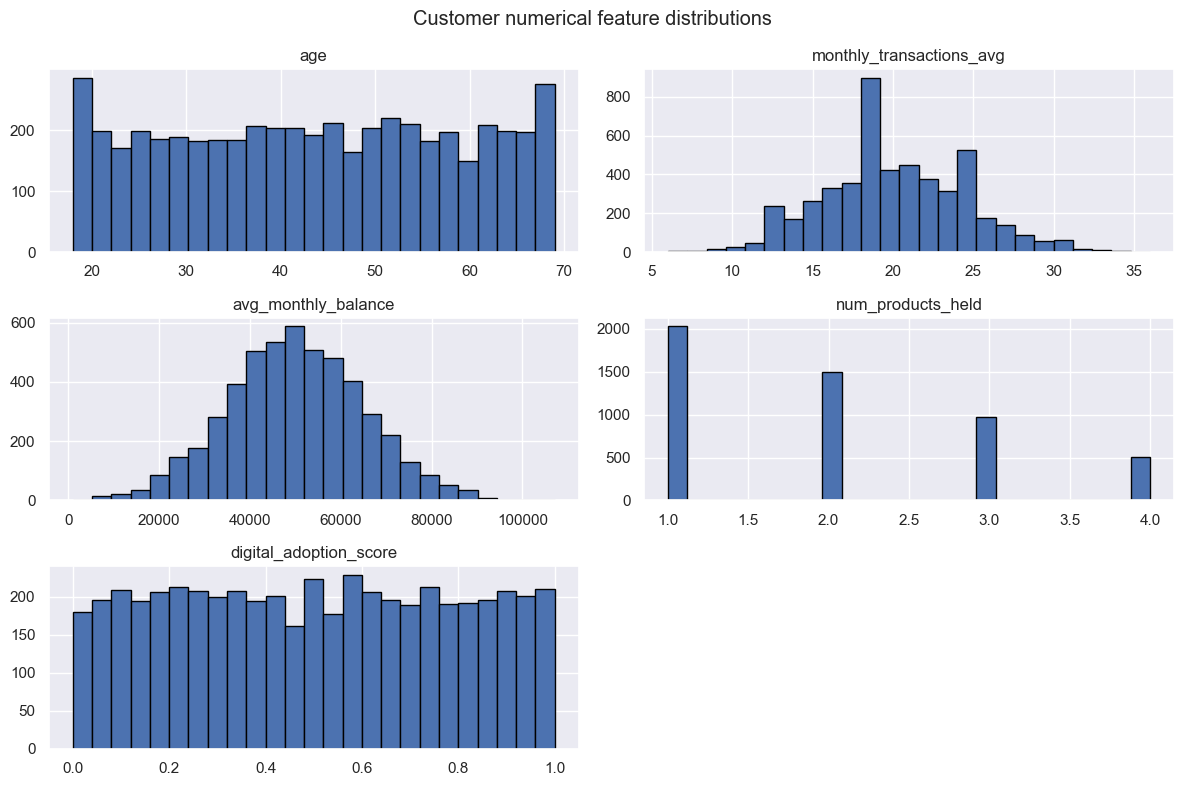

In [18]:
numeric_customer_cols = [
    "age", "monthly_transactions_avg", "avg_monthly_balance",
    "num_products_held", "digital_adoption_score"
]
customers[numeric_customer_cols].hist(figsize=(12, 8), bins=25, edgecolor="black")
plt.suptitle("Customer numerical feature distributions")
plt.tight_layout()
plt.show()


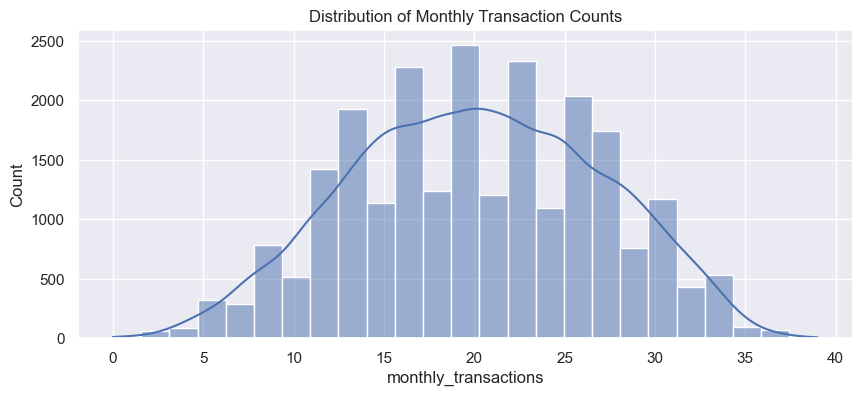

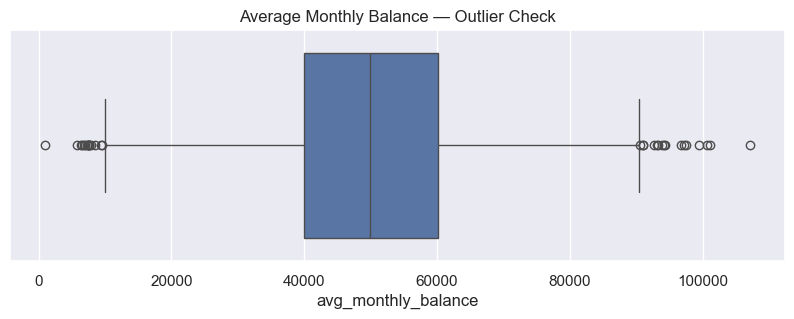

In [19]:
plt.figure(figsize=(10, 4))
sns.histplot(data=transactions, x="monthly_transactions", bins=25, kde=True)
plt.title("Distribution of Monthly Transaction Counts")
plt.show()

plt.figure(figsize=(10, 3))
sns.boxplot(data=customers, x="avg_monthly_balance")
plt.title("Average Monthly Balance — Outlier Check")
plt.show()


## 4. Category-wise comparisons

These plots help compare customer behavior across region and preferred channel. Interpret observed differences as patterns, not proof of cause.


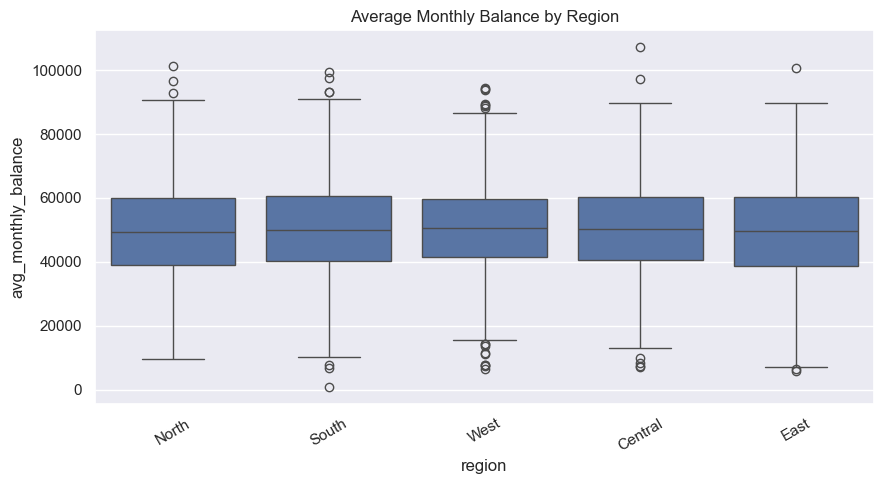

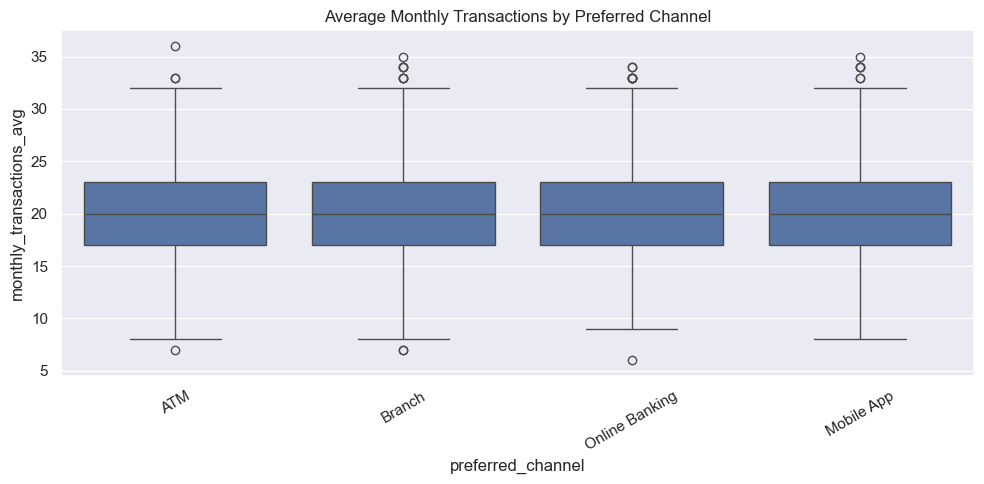

In [20]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=customers, x="region", y="avg_monthly_balance")
plt.title("Average Monthly Balance by Region")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=customers, x="preferred_channel", y="monthly_transactions_avg")
plt.title("Average Monthly Transactions by Preferred Channel")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 5. Multivariate analysis — correlation

Correlation measures linear relationships between numerical variables. Exclude identifiers. Binary flags can be included for exploratory analysis, but correlation does not prove causation.


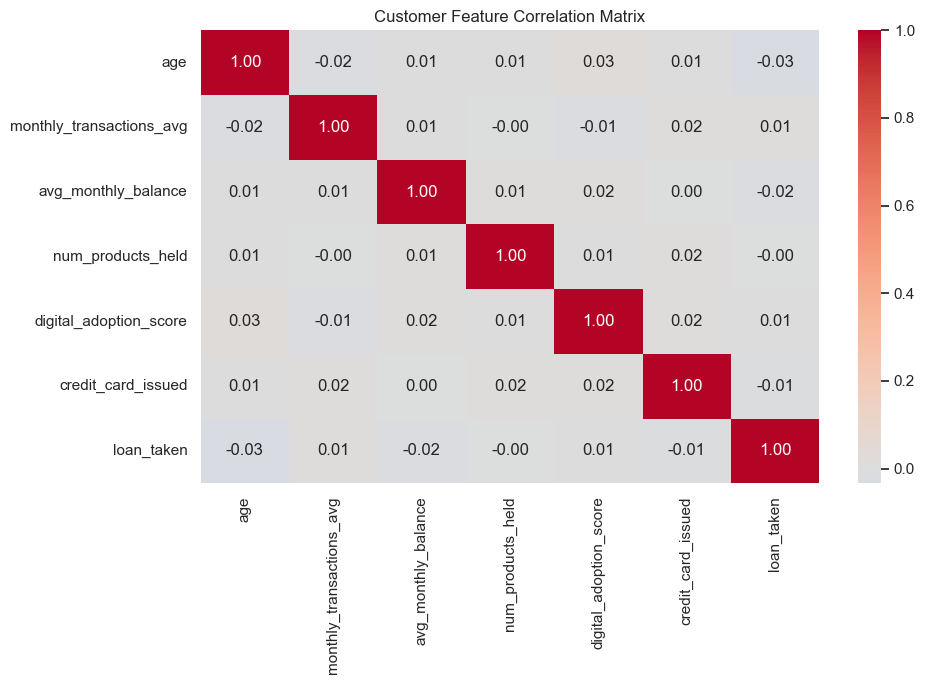

,age,monthly_transactions_avg,avg_monthly_balance,num_products_held,digital_adoption_score,credit_card_issued,loan_taken
age,1.000000,-0.019696,0.005931,0.010055,0.026655,0.009737,-0.033751
monthly_transactions_avg,-0.019696,1.000000,0.006484,-0.002071,-0.014370,0.016276,0.012871
avg_monthly_balance,0.005931,0.006484,1.000000,0.011242,0.016889,0.000352,-0.015280
num_products_held,0.010055,-0.002071,0.011242,1.000000,0.006627,0.017927,-0.003816
digital_adoption_score,0.026655,-0.014370,0.016889,0.006627,1.000000,0.017911,0.007073
credit_card_issued,0.009737,0.016276,0.000352,0.017927,0.017911,1.000000,-0.006004
loan_taken,-0.033751,0.012871,-0.015280,-0.003816,0.007073,-0.006004,1.000000


In [21]:
numeric_cols = [
    "age", "monthly_transactions_avg", "avg_monthly_balance",
    "num_products_held", "digital_adoption_score",
    "credit_card_issued", "loan_taken"
]
corr = customers[numeric_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Customer Feature Correlation Matrix")
plt.tight_layout()
plt.show()

display(corr)


## 6. Save cleaned outputs

The CSVs below are created in the notebook's current working folder.
- `cleaned_customers.csv`: cleaned customer-level data.
- `cleaned_transactions.csv`: cleaned monthly trend data with datetime month.
- `merged_monthly_customer_data.csv`: transaction-month rows with customer features.
- `customer_level_trend_summary.csv`: one row per customer, retaining customers without observed transaction history.
- `data_profiling_summary.csv`: profiling report.


In [22]:
customers.to_csv("cleaned_customers.csv", index=False)
transactions.to_csv("cleaned_transactions.csv", index=False)
merged_monthly.to_csv("merged_monthly_customer_data.csv", index=False)
customer_summary.to_csv("customer_level_trend_summary.csv", index=False)

print("Saved all cleaned datasets and the profiling summary.")
print("Customer dataset:", customers.shape)
print("Transaction dataset:", transactions.shape)
print("Merged monthly dataset:", merged_monthly.shape)
print("Customer-level summary:", customer_summary.shape)


Saved all cleaned datasets and the profiling summary.
Customer dataset: (5000, 10)
Transaction dataset: (24000, 3)
Merged monthly dataset: (24000, 12)
Customer-level summary: (5000, 15)


## 7. Initial observations from the supplied files

- Customer dataset: 5,000 rows and 10 columns.
- Transaction dataset: 24,000 rows and 3 columns.
- Both files have no missing values and no exact duplicate rows at initial inspection.
- Customer IDs are unique in the customer file.
- The transaction file contains 1,000 customers, each with 24 monthly observations from January 2022 through December 2023.
- There are 4 zero monthly transaction counts. These should be checked but not automatically removed.
- The customer table has 5,000 customers, so 4,000 have no transaction rows in this supplied transaction file. Confirm with the mentor whether the transaction dataset is intentionally a subset.
- `digital_adoption_score` ranges from 0 to 1; `credit_card_issued` and `loan_taken` are binary flags.


## 8. Detailed EDA Findings and Business Interpretation

### 8.1 Customer Demographics and Financial Behavior

The customer dataset contains 5,000 records. Customer age ranges from 18 to 69 years, with an average age of approximately 43.6 years. This indicates that the dataset includes customers from different age groups.

The average monthly balance is approximately 50,151 currency units. The balance values range from 1,000 to 107,100, showing variation in customers' financial positions. The bank could investigate customer segments with higher balances to identify opportunities for suitable savings products and personalized financial services.

Customers hold between one and four banking products, with an average of approximately two products per customer. This information can help the bank explore opportunities for cross-selling relevant products to customers who currently hold fewer products.

### 8.2 Digital Banking Adoption

The digital adoption score ranges from 0 to 1, with an average of approximately 0.497. This suggests that the average score is close to the midpoint of the scale.

The bank can examine customers with lower digital adoption scores and explore whether additional digital banking guidance or awareness programs could improve adoption. The score's precise interpretation should be confirmed using the dataset's business definition.

### 8.3 Transaction Behavior and Monthly Trends

The transaction dataset contains 24 monthly observations for each of 1,000 customers, covering January 2022 through December 2023.

The average monthly transaction count is approximately 20.1, while the minimum is zero and the maximum is 39. Four monthly records have zero transactions. These records should be investigated to determine whether they represent genuine inactivity or data-collection issues.

The monthly trend chart should be reviewed to identify increases, decreases, and possible recurring patterns. These observations can help the bank investigate changes in customer activity and plan appropriate engagement strategies.

### 8.4 Regional and Banking Channel Analysis

The customer dataset includes customers from the North, South, East, West, and Central regions. It also includes customers whose preferred channels are Branch, ATM, Online Banking, and Mobile App.

Comparing average monthly balances across regions can help identify differences in customer financial behavior. Comparing transaction activity across preferred channels can help the bank understand how customers use its banking services.

Business recommendations should be based on the actual values displayed in the charts rather than assumptions about which region or channel performs best.

### 8.5 Correlation and Relationships Between Features

The correlation heatmap helps identify numerical features that move together. Positive correlations indicate that two features tend to increase together, while negative correlations indicate that one tends to decrease as the other increases.

Strong correlations should be examined to understand whether features provide overlapping information. Correlation alone does not prove a causal relationship.

### 8.6 Data Quality and Preparation Decisions

Initial inspection found no missing values or exact duplicate rows in either dataset. Therefore, missing-value imputation and duplicate removal were not required at the initial inspection stage.

The customer IDs are unique in the customer dataset. The transaction dataset contains monthly customer-level records rather than individual transaction records. Dates should be converted into a valid datetime format before time-based analysis.

The customer table contains 5,000 customers, while the transaction file represents 1,000 customers. The remaining 4,000 customers should not automatically be assigned zero transactions because their transaction history is absent from the supplied file.

The four zero monthly transaction counts should also be retained unless further investigation establishes that they are invalid.

### 8.7 Limitations and Future Work

The supplied datasets do not contain an account-opening date, so actual account tenure cannot be calculated from the available fields.

The transaction history covers only 24 months and only a subset of customers. Any forecasting model should account for these limitations and should be evaluated using an appropriate time-based validation strategy.

Further work could include forecasting monthly transaction activity, identifying changes in customer engagement, and developing customer segments to help the bank investigate potential business opportunities.
